# Cyber Shield — Logistic Regression ilə şübhəli girişlərin aşkarlanması

**Məqsəd:** giriş qeydlərinə əsasən `risky_login` (0 = normal, 1 = riskli) proqnozlaşdırmaq.  
**Qeyd:** məlumatlar süni yaradılıb, real istifadəçi və hücum qeydləri deyil.

## 1. Məlumatı tanıyaq (EDA)

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score)

df = pd.read_csv("CyberShield_LogisticRegression_Dataset.csv")
df.head()

,login_id,login_hour,failed_attempts_24h,unknown_device,new_country,ip_risk_score,password_reset_7d,two_factor_enabled,account_age_days,last_login_gap_hours,vpn_used,risky_login
0,LOG-1101,15,1,1,0,40.6,0,1,100,20.0,0,0
1,LOG-0901,7,0,0,0,28.3,0,1,551,1.0,0,0
2,LOG-0758,0,0,1,1,43.8,0,1,423,19.0,0,1
3,LOG-0693,7,0,0,0,35.0,0,0,2522,8.0,0,1
4,LOG-0111,9,0,0,1,38.7,0,0,105,NaN,1,0


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   login_id              1200 non-null   str    
 1   login_hour            1200 non-null   int64  
 2   failed_attempts_24h   1200 non-null   int64  
 3   unknown_device        1200 non-null   int64  
 4   new_country           1200 non-null   int64  
 5   ip_risk_score         1182 non-null   float64
 6   password_reset_7d     1200 non-null   int64  
 7   two_factor_enabled    1200 non-null   int64  
 8   account_age_days      1200 non-null   int64  
 9   last_login_gap_hours  1176 non-null   float64
 10  vpn_used              1200 non-null   int64  
 11  risky_login           1200 non-null   int64  
dtypes: float64(2), int64(9), str(1)
memory usage: 112.6 KB


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
login_hour,1200.0,11.645000,6.469326,0.0,7.00,11.0,17.00,23.0
failed_attempts_24h,1200.0,1.108333,1.047622,0.0,0.00,1.0,2.00,6.0
unknown_device,1200.0,0.180833,0.385040,0.0,0.00,0.0,0.00,1.0
new_country,1200.0,0.125833,0.331800,0.0,0.00,0.0,0.00,1.0
ip_risk_score,1182.0,38.184687,18.920628,1.6,23.50,36.7,50.60,95.4
password_reset_7d,1200.0,0.107500,0.309877,0.0,0.00,0.0,0.00,1.0
two_factor_enabled,1200.0,0.663333,0.472767,0.0,0.00,1.0,1.00,1.0
account_age_days,1200.0,579.360833,647.128518,7.0,161.75,339.5,724.25,3000.0
last_login_gap_hours,1176.0,23.651361,30.996651,1.0,6.00,14.0,28.00,320.0
vpn_used,1200.0,0.150000,0.357220,0.0,0.00,0.0,0.00,1.0


In [4]:
df.isna().sum()

login_id                 0
login_hour               0
failed_attempts_24h      0
unknown_device           0
new_country              0
ip_risk_score           18
password_reset_7d        0
two_factor_enabled       0
account_age_days         0
last_login_gap_hours    24
vpn_used                 0
risky_login              0
dtype: int64

risky_login
0    838
1    362
Name: count, dtype: int64 

risky_login
0    69.8 %
1    30.2 %
Name: count, dtype: str


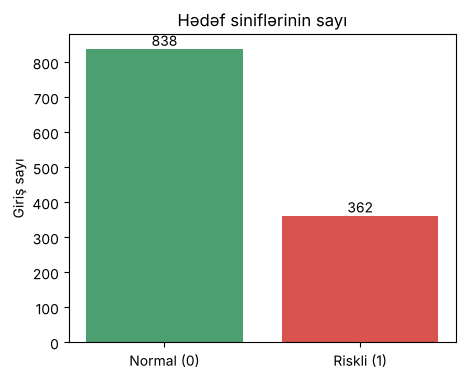

In [5]:
counts = df["risky_login"].value_counts().sort_index()
print(counts, "\n")
print((counts / len(df) * 100).round(1).astype(str) + " %")

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(["Normal (0)", "Riskli (1)"], counts.values, color=["#4C9F70", "#D9534F"])
ax.bar_label(bars)
ax.set_title("Hədəf siniflərinin sayı")
ax.set_ylabel("Giriş sayı")
plt.show()

**Şərh:** data qeyri-balanslıdır — normal girişlər riskli girişlərdən təxminən 2.3 dəfə çoxdur (838 vs 362). Buna görə yalnız accuracy-yə baxmaq yanıldıcı ola bilər; Precision, Recall və F1 də baxılmalıdır.  
`ip_risk_score` (18) və `last_login_gap_hours` (24) sütunlarında boş xanalar var.

## 2. Hazırlıq
- `login_id` identifikatordur, modelə daxil edilmir.
- Train/Test = 80/20, `stratify=y`.
- Boşluqların doldurulması (median) və `StandardScaler` **yalnız train üzərində fit** edilir (data leakage olmasın).

In [6]:
X = df.drop(columns=["login_id", "risky_login"])
y = df["risky_login"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

imputer = SimpleImputer(strategy="median").fit(X_train)
scaler = StandardScaler().fit(imputer.transform(X_train))

X_train_s = scaler.transform(imputer.transform(X_train))
X_test_s  = scaler.transform(imputer.transform(X_test))

print("Train:", X_train_s.shape, "| Test:", X_test_s.shape)
print("Train-də riskli payı:", round(y_train.mean(), 3), "| Test-də:", round(y_test.mean(), 3))

Train: (960, 10) | Test: (240, 10)
Train-də riskli payı: 0.302 | Test-də: 0.3


## 3. Modeli öyrədək

In [7]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_s, y_train)

y_pred  = model.predict(X_test_s)               # hədd = 0.50
y_proba = model.predict_proba(X_test_s)[:, 1]   # riskli olma ehtimalı
print(y_pred[:10]); print(y_proba[:10].round(3))

[0 0 0 0 0 0 0 0 0 0]
[0.267 0.301 0.124 0.107 0.194 0.26  0.126 0.415 0.493 0.067]


## 4. Səhvləri araşdıraq (hədd = 0.50)

In [8]:
def evaluate(y_true, proba, thr):
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {"Hədd": thr, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "Accuracy": accuracy_score(y_true, pred),
            "Precision": precision_score(y_true, pred),
            "Recall": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred)}

res_050 = evaluate(y_test, y_proba, 0.50)
pd.Series(res_050).round(3)

Hədd           0.500
TN           149.000
FP            19.000
FN            45.000
TP            27.000
Accuracy       0.733
Precision      0.587
Recall         0.375
F1             0.458
dtype: float64

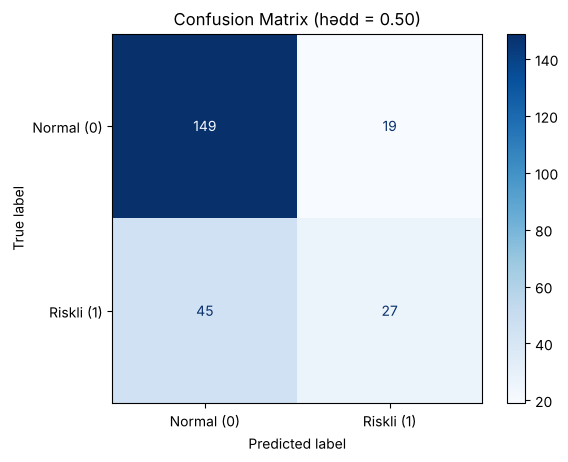

In [9]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Normal (0)", "Riskli (1)"]).plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix (hədd = 0.50)")
plt.show()

### FP və FN nə deməkdir?
- **False Positive (FP):** giriş əslində *normaldır*, model isə *riskli* deyib. Nəticə: təhlükəsizlik komandası lazımsız yoxlama aparır, istifadəçi narahat olur (**yalançı həyəcan**).
- **False Negative (FN):** giriş əslində *risklidir*, model isə *normal* deyib. Nəticə: təhlükəli giriş **gözdən qaçır**, hesab ələ keçirilə bilər.

**Hansı daha təhlükəlidir? — FN.** FP-nin dəyəri vaxt və narahatlıqdır, FN-in dəyəri isə hesabın oğurlanması və data sızmasıdır. Ona görə kibertəhlükəsizlikdə əsas hədəf **Recall-u** (riskli girişlərin nə qədərini tutduğumuzu) yüksək saxlamaqdır.

## 5. Model əmsalları

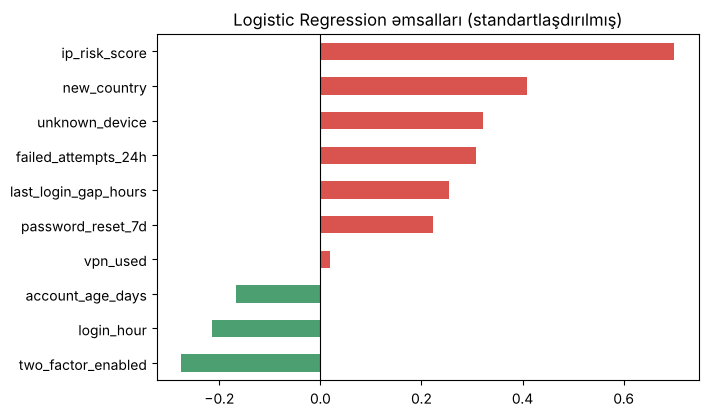

ip_risk_score           0.700
new_country             0.410
unknown_device          0.322
failed_attempts_24h     0.309
last_login_gap_hours    0.255
password_reset_7d       0.222
vpn_used                0.018
account_age_days       -0.168
login_hour             -0.215
two_factor_enabled     -0.275
dtype: float64

In [10]:
coef = pd.Series(model.coef_[0], index=X.columns).sort_values()
colors = ["#D9534F" if v > 0 else "#4C9F70" for v in coef.values]
ax = coef.plot(kind="barh", color=colors, figsize=(7, 4.5))
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Logistic Regression əmsalları (standartlaşdırılmış)")
plt.show()
coef.sort_values(ascending=False).round(3)

**Şərh:** əmsalı müsbət olan siqnallar riski artırır, mənfi olanlar azaldır. Ən güclü risk siqnalı `ip_risk_score`-dur, sonra `new_country`, `unknown_device` və `failed_attempts_24h` gəlir. `two_factor_enabled` (2FA aktivdir) riski azaldır. `vpn_used` demək olar ki, təsirsizdir (≈0).

## 6. Qərar: hədd 0.30 vs 0.50

In [11]:
comp = pd.DataFrame([evaluate(y_test, y_proba, t) for t in (0.50, 0.30)]).set_index("Hədd").round(3)
comp

,TN,FP,FN,TP,Accuracy,Precision,Recall,F1
Hədd,,,,,,,,
0.5,149,19,45,27,0.733,0.587,0.375,0.458
0.3,129,39,20,52,0.754,0.571,0.722,0.638


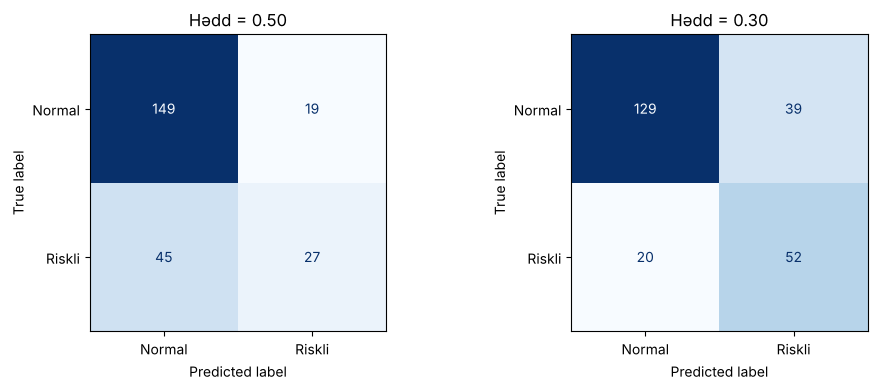

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, t in zip(axes, (0.50, 0.30)):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (y_proba >= t).astype(int)),
                           display_labels=["Normal", "Riskli"]).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"Hədd = {t:.2f}")
plt.tight_layout(); plt.show()

**Nəticə:** hədd **0.30** daha çox riskli girişi tutur — Recall təxminən **0.38 → 0.72** qalxır, FN sayı isə **45 → 20** enir. Bunun əvəzi FP-nin artmasıdır (**19 → 39**), yəni daha çox normal giriş əlavə yoxlamaya düşür. Accuracy demək olar ki, dəyişmir, F1 isə xeyli yaxşılaşır (≈0.46 → 0.64).

**Qərar:** təhlükəsizlik baxımından FN daha bahalı olduğu üçün **0.30 hədd daha məqsədəuyğundur**. Əlavə yoxlama yükü qəbul edilə biləndirsə, bu hədd seçilməlidir.

## 7. 3 yeni giriş üçün proqnoz

In [13]:
new_logins = pd.DataFrame([
    # login_hour, failed_24h, unknown_dev, new_country, ip_risk, pwd_reset, 2FA, acc_age, gap_h, vpn
    [3, 6, 1, 1, 88.0, 1, 0,   20,  250.0, 1],   # şübhəli: gecə, çox uğursuz cəhd, yeni ölkə/cihaz
    [14, 0, 0, 0, 12.0, 0, 1, 1800,   10.0, 0],  # adi: iş saatı, tanış cihaz, 2FA aktiv
    [22, 2, 1, 0, 55.0, 0, 1,  300,   40.0, 1],  # orta: qarışıq siqnallar
], columns=X.columns)

proba_new = model.predict_proba(scaler.transform(imputer.transform(new_logins)))[:, 1]
out = new_logins.copy()
out["risk_ehtimalı"]  = proba_new.round(3)
out["proqnoz_0.50"]   = np.where(proba_new >= 0.50, "Riskli", "Normal")
out["proqnoz_0.30"]   = np.where(proba_new >= 0.30, "Riskli", "Normal")
out

,login_hour,failed_attempts_24h,unknown_device,new_country,ip_risk_score,password_reset_7d,two_factor_enabled,account_age_days,last_login_gap_hours,vpn_used,risk_ehtimalı,proqnoz_0.50,proqnoz_0.30
0,3,6,1,1,88.0,1,0,20,250.0,1,0.999,Riskli,Riskli
1,14,0,0,0,12.0,0,1,1800,10.0,0,0.032,Normal,Normal
2,22,2,1,0,55.0,0,1,300,40.0,1,0.511,Riskli,Riskli


## 8. Yekun izah

- **Data:** 1200 giriş, 10 xüsusiyyət; 838 normal, 362 riskli (qeyri-balanslı). İki sütunda boşluq var, median ilə doldurulub (train-dən öyrənilib).
- **Model:** Logistic Regression, 80/20 stratify bölgü, scaler və imputer yalnız train üzərində fit olunub.
- **Ən vacib siqnallar:** `ip_risk_score`, `new_country`, `unknown_device`, `failed_attempts_24h`; 2FA riski azaldır.
- **Səhv növü:** FN (riskli girişi buraxmaq) FP-dən təhlükəlidir.
- **Tövsiyə:** hədd 0.30 — Recall əhəmiyyətli dərəcədə yüksəlir; bunun qiyməti əlavə yoxlama yüküdür.
- **Məhdudiyyət:** data süni olduğundan real sistemdə nəticələr fərqli ola bilər.